# ЛР 7. Построение автокодировщика — вариант 18
Беспалый Максим Евгеньевич, Т26ИИКТ-МИК11. Набор 3 «disc_noise» × фактор 6 «4096 → 512 сцен (20 → 160 эпох, 640 шагов)».
Серия seed 101…105. Гипотеза, допуск и дополнительные проверки E1–E3 записаны в журнал до запуска.

**Запуск:** «Среда выполнения» → «Сменить среду выполнения» → «Графический процессор T4» → «Сохранить» → «Выполнить все» (≈ 4–6 минут).

## Ячейка 1. Среда (шаг 1)

In [1]:
!nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv
import sys, platform, datetime, torch, numpy
print("UTC:", datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"))
print("python", sys.version.split()[0], "|", platform.platform(), "| numpy", numpy.__version__)
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "НЕТ GPU — смените среду на T4")

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.82.07
UTC: 2026-10-17 23:32:20
python 3.13.15 | Linux-6.6.122+-x86_64-with-glibc2.39 | numpy 2.1.3
torch 2.11.0+cu130 | CUDA 13.0 | GPU: Tesla T4


## Ячейка 2. lab07_lib.py (приложение А МУ, без изменений)

In [2]:
%%writefile lab07_lib.py
# ЛР 7. Построение автокодировщика. Библиотека учебных функций.
# Проверено 19.09.2026: Google Colab, GPU T4, Python 3.13, torch 2.11.0+cu128. Внешние данные не нужны: сцены порождаются кодом.
import time
import numpy as np
import torch
import torch.nn as nn

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
N = 32                      # сторона изображения
SEEDS = range(101, 106)     # серия seed обучения
KINDS = ["disc", "disc_rect", "disc_noise", "disc_color", "two_discs"]   # пять контекстов (наборов данных)
N_FACTORS = {"disc": 3, "disc_rect": 4, "disc_noise": 3, "disc_color": 4, "two_discs": 4}
AMBER, GREEN, PINK = (1.0, 0.76, 0.29), (0.24, 0.86, 0.60), (0.95, 0.35, 0.55)
_YY, _XX = np.mgrid[0:N, 0:N] / (N - 1)


def _disc(img, cx, cy, r, color):
    m = (_XX - cx) ** 2 + (_YY - cy) ** 2 <= r * r
    for k in range(3):
        img[k][m] = color[k]


def _hue(h):
    """Простой цвет по параметру 0..1 (три сдвинутые косинусоиды)."""
    return tuple(0.5 + 0.5 * np.cos(2 * np.pi * (h + s)) for s in (0.0, 1 / 3, 2 / 3))


def render(kind, f):
    """Сцена 3×N×N по вектору факторов f из отрезка [0, 1]: положения и размеры объектов задают изображение однозначно."""
    img = np.zeros((3, N, N), dtype=np.float32)
    img[:] = (0.10 + 0.25 * (_XX + _YY) / 2)[None]
    if kind in ("disc", "disc_noise"):
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], AMBER)
    elif kind == "disc_rect":
        _disc(img, 0.25 + 0.5 * f[0], 0.30 + 0.25 * f[1], 0.12 + 0.08 * f[2], AMBER)
        x0 = int((0.05 + 0.55 * f[3]) * N); img[:, int(0.72 * N):int(0.92 * N), x0:x0 + int(0.3 * N)] = np.array(GREEN)[:, None, None]
    elif kind == "disc_color":
        _disc(img, 0.25 + 0.5 * f[0], 0.25 + 0.5 * f[1], 0.12 + 0.10 * f[2], _hue(f[3]))
    elif kind == "two_discs":
        _disc(img, 0.15 + 0.3 * f[0], 0.15 + 0.7 * f[1], 0.12, AMBER)
        _disc(img, 0.55 + 0.3 * f[2], 0.15 + 0.7 * f[3], 0.12, PINK)
    else:
        raise ValueError(kind)
    return img


_CACHE = {}


def dataset(kind, n_train=4096, n_test=1024):
    """Обучающая и тестовая выборки (тензоры на устройстве) и факторы. Данные одинаковы для всех запусков (seed 7)."""
    if kind not in _CACHE:
        rng = np.random.default_rng(7)
        f = rng.random((n_train + n_test, N_FACTORS[kind]))
        x = np.stack([render(kind, fi) for fi in f])
        if kind == "disc_noise":
            x = np.clip(x + 0.05 * rng.standard_normal(x.shape).astype(np.float32), 0, 1)
        X = torch.tensor(x, dtype=torch.float32, device=DEVICE); F = torch.tensor(f, dtype=torch.float32, device=DEVICE)
        _CACHE[kind] = (X[:n_train], X[n_train:], F[:n_train], F[n_train:])
    return _CACHE[kind]


class ConvAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Conv2d(3, 16, 4, 2, 1), nn.ReLU(), nn.Conv2d(16, 32, 4, 2, 1), nn.ReLU(),
                                 nn.Conv2d(32, 64, 4, 2, 1), nn.ReLU(), nn.Flatten(), nn.Linear(64 * 16, d))
        self.dec_fc = nn.Sequential(nn.Linear(d, 64 * 16), nn.ReLU())
        self.dec = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 16, 4, 2, 1), nn.ReLU(),
                                 nn.ConvTranspose2d(16, 3, 4, 2, 1), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(self.dec_fc(z).view(-1, 64, 4, 4))

    def forward(self, x):
        return self.decode(self.encode(x))


class DenseAE(nn.Module):
    def __init__(self, d):
        super().__init__()
        self.enc = nn.Sequential(nn.Flatten(), nn.Linear(3 * N * N, 256), nn.ReLU(), nn.Linear(256, d))
        self.dec = nn.Sequential(nn.Linear(d, 256), nn.ReLU(), nn.Linear(256, 3 * N * N), nn.Sigmoid())

    def encode(self, x):
        return self.enc(x)

    def decode(self, z):
        return self.dec(z).view(-1, 3, N, N)

    def forward(self, x):
        return self.decode(self.encode(x))


def build(arch, d):
    return (ConvAE if arch == "conv" else DenseAE)(d).to(DEVICE)


def n_params(model):
    return sum(p.numel() for p in model.parameters())


def psnr_images(x, y):
    """Средний по изображениям PSNR, дБ (значения 0..1)."""
    mse = ((x - y) ** 2).flatten(1).mean(1).clamp_min(1e-10)
    return float((10 * torch.log10(1.0 / mse)).mean())


def train(model, Xtr, epochs=20, lr=2e-3, loss="mse", noise=0.0, seed=0, batch=128):
    """Обучение с Adam. loss: 'mse' или 'l1'. noise > 0: вход зашумляется (шумоподавляющий автокодировщик), цель — чистое изображение."""
    g = torch.Generator(device="cpu").manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    n = Xtr.shape[0]
    for _ in range(epochs):
        perm = torch.randperm(n, generator=g).to(DEVICE)
        for i in range(0, n, batch):
            x = Xtr[perm[i:i + batch]]
            xin = (x + noise * torch.randn(x.shape, generator=g).to(DEVICE)).clamp(0, 1) if noise > 0 else x
            out = model(xin)
            l = ((out - x) ** 2).mean() if loss == "mse" else (out - x).abs().mean()
            opt.zero_grad(); l.backward(); opt.step()
    return model


@torch.no_grad()
def reconstruct(model, X, eval_noise=0.0, seed=1234):
    model.eval()
    if eval_noise > 0:
        g = torch.Generator(device="cpu").manual_seed(seed)
        X = (X + eval_noise * torch.randn(X.shape, generator=g).to(DEVICE)).clamp(0, 1)
    return model(X)


# Шесть факторов: изменение базового режима A (свёрточный автокодировщик, d = 8, MSE, чистые данные, 4096 примеров).
FACTORS = ["latent_8_to_2", "latent_8_to_32", "arch_conv_to_dense", "loss_mse_to_l1", "input_clean_to_denoising", "train_4096_to_512"]
BASE = dict(arch="conv", d=8, loss="mse", noise=0.0, eval_noise=0.0, n_train=4096, epochs=20)


def settings(factor):
    a, b = dict(BASE), dict(BASE)
    if factor == "latent_8_to_2":
        b["d"] = 2
    elif factor == "latent_8_to_32":
        b["d"] = 32
    elif factor == "arch_conv_to_dense":
        b["arch"] = "dense"
    elif factor == "loss_mse_to_l1":
        b["loss"] = "l1"
    elif factor == "input_clean_to_denoising":
        a["eval_noise"] = b["eval_noise"] = 0.2; b["noise"] = 0.2
    elif factor == "train_4096_to_512":
        b["n_train"] = 512; b["epochs"] = 160   # 512 / 128 * 160 = 640 шагов, как 4096 / 128 * 20: число обновлений весов сохранено
    else:
        raise ValueError(factor)
    return a, b


def run(kind, cfg, seed):
    """Одно обучение: метрики на тестовой выборке."""
    Xtr, Xte, _, _ = dataset(kind)
    Xtr = Xtr[:cfg["n_train"]]
    torch.manual_seed(seed)
    t0 = time.perf_counter()
    model = train(build(cfg["arch"], cfg["d"]), Xtr, cfg["epochs"], loss=cfg["loss"], noise=cfg["noise"], seed=seed)
    if DEVICE == "cuda":
        torch.cuda.synchronize()
    dt = time.perf_counter() - t0
    p_te = psnr_images(reconstruct(model, Xte, cfg["eval_noise"]), Xte)
    p_tr = psnr_images(reconstruct(model, Xtr[:1024], cfg["eval_noise"]), Xtr[:1024])
    return dict(psnr=p_te, gap=p_tr - p_te, params=n_params(model) / 1000, seconds=dt), model


def variant_summary(n, seeds=SEEDS):
    """Вариант n = 1..30: набор данных c = (n-1)//6, фактор k = (n-1)%6. Для каждой метрики: A, s, B, разность, |d|/s, признак |d| > 2s."""
    c, k = (n - 1) // 6, (n - 1) % 6
    a_cfg, b_cfg = settings(FACTORS[k])
    A = {m: [] for m in ("psnr", "gap", "params", "seconds")}
    B = {m: [] for m in A}
    run(KINDS[c], a_cfg, 0)  # прогрев
    for s in seeds:
        ma, _ = run(KINDS[c], a_cfg, s)
        mb, _ = run(KINDS[c], b_cfg, s)
        for m in A:
            A[m].append(ma[m]); B[m].append(mb[m])
    rows = []
    for m in A:
        d = np.mean(B[m]) - np.mean(A[m]); sa = np.std(A[m], ddof=1)
        rows.append((m, float(np.mean(A[m])), float(sa), float(np.mean(B[m])), float(d), float(abs(d) / sa) if sa > 0 else float("inf"), bool(abs(d) > 2 * sa)))
    return dict(variant=n, ctx=c + 1, factor=FACTORS[k], rows=rows)

Writing lab07_lib.py


## Ячейка 3. Сверка библиотеки (8679 байт, SHA-256 d84b83a8…)

In [3]:
import hashlib, pathlib
b = pathlib.Path("lab07_lib.py").read_bytes()
for name, x in (("как записан", b), ("с \\n в конце", b.rstrip(b"\n") + b"\n")):
    h = hashlib.sha256(x).hexdigest(); print(f"{name}: {len(x)} байт, SHA-256 {h[:16]}…", "— совпадает с эталоном" if h.startswith("d84b83a8") else "")

как записан: 8679 байт, SHA-256 d84b83a878f55e95… — совпадает с эталоном
с \n в конце: 8679 байт, SHA-256 d84b83a878f55e95… — совпадает с эталоном


## Ячейка 4. Демонстрационный вариант 1 — как в МУ (воспроизведение, продвинутый уровень)

In [4]:
# ЛР 7. Демонстрационный вариант 1: набор «диск», фактор «размер латентного вектора 8 → 2».
import numpy as np
import lab07_lib as L

N = 1
c, k = (N - 1) // 6, (N - 1) % 6
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("A:", a_cfg)
print("B:", b_cfg)

# Серия из пяти seed: метрики режимов A и B
result = L.variant_summary(N)
for name, a, s, b, d, q, sig in result["rows"]:
    print(f"{name:8s} A={a:8.3f} s={s:6.3f} B={b:8.3f} d={d:+8.3f} |d|/s={q:7.2f} 2s={'да' if sig else 'нет'}")

# Тривиальный эталон: средняя картинка обучающей выборки, одинаковая для всех входов
Xtr, Xte, Ftr, Fte = L.dataset(L.KINDS[c])
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(L.psnr_images(mean_image, Xte), 3))

# Диагностика: PSNR в зависимости от размера латентного вектора (seed 101, 102, 103)
for d in (1, 2, 3, 4, 8):
    vals = [L.run(L.KINDS[c], dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

# Лист сравнения comparison.png: оригиналы, реконструкции режима A и режима B (seed 101, первые 8 тестовых сцен)
from PIL import Image
rows = [Xte[:8]]
for cfg in (a_cfg, b_cfg):
    model = L.run(L.KINDS[c], cfg, 101)[1]
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([np.concatenate(list(r.permute(0, 2, 3, 1).cpu().numpy()), axis=1) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save("comparison.png")
sheet
import shutil; shutil.move("comparison.png", "comparison_variant01.png")
DEMO_ROWS = result["rows"]

A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'conv', 'd': 2, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
psnr     A=  26.164 s= 0.662 B=  23.207 d=  -2.957 |d|/s=   4.46 2s=да
gap      A=   0.041 s= 0.009 B=   0.099 d=  +0.057 |d|/s=   6.35 2s=да
params   A= 101.035 s= 0.000 B=  88.741 d= -12.294 |d|/s=    inf 2s=да
seconds  A=   1.745 s= 0.024 B=   1.728 d=  -0.016 |d|/s=   0.66 2s=нет
эталон «средняя картинка», PSNR на тесте: 17.171
d=1: PSNR = 20.62 дБ (по seed: 20.58, 20.78, 20.49)
d=2: PSNR = 23.16 дБ (по seed: 23.28, 23.45, 22.75)
d=3: PSNR = 25.23 дБ (по seed: 24.88, 24.64, 26.18)
d=4: PSNR = 26.43 дБ (по seed: 26.76, 26.34, 26.18)
d=8: PSNR = 25.76 дБ (по seed: 25.61, 26.61, 25.07)


## Ячейка 5. Вариант 18: режимы A и B, variant_summary(18), классификация по допуску (шаги 3, 4, 7)

In [5]:
import json, time, numpy as np, torch, importlib
import lab07_lib as L
importlib.reload(L)
N = 18
c, k = (N - 1) // 6, (N - 1) % 6
KIND = L.KINDS[c]
OUT = pathlib.Path("artifacts/v18"); OUT.mkdir(parents=True, exist_ok=True)
a_cfg, b_cfg = L.settings(L.FACTORS[k])
print("набор:", KIND, "| фактор:", L.FACTORS[k])
print("A:", a_cfg); print("B:", b_cfg)
print("различаются поля:", [key for key in a_cfg if a_cfg[key] != b_cfg[key]],
      "| шагов обучения A, B:", a_cfg["n_train"] // 128 * a_cfg["epochs"], b_cfg["n_train"] // 128 * b_cfg["epochs"])
t0 = time.perf_counter(); res = L.variant_summary(N); print(f"серия: {time.perf_counter() - t0:.0f} с")
TOL = {"psnr": ("abs", 1.0), "gap": ("abs", 0.1), "params": ("abs", 0.0), "seconds": ("rel", 0.20)}
def classify(m, a, d):
    kind, t = TOL[m]
    if m == "params": return "без изменений" if d == 0 else "изменилось"
    x = d if kind == "abs" else d / a
    if abs(x) <= t: return "нейтрально"
    return {"psnr": ("улучшение" if x > 0 else "ухудшение"), "gap": ("переобучение сильнее" if x > 0 else "переобучение слабее"),
            "seconds": ("медленнее" if x > 0 else "быстрее")}[m]
ROWS = []
print(f"\n{'метрика':8s} {'A':>9s} {'s':>7s} {'B':>9s} {'Δ':>9s} {'|Δ|/s':>8s} 2s   допуск")
for name, a, s, b, d, q, sig in res["rows"]:
    cl = classify(name, a, d); ROWS.append(dict(metric=name, A=a, s=s, B=b, d=d, ratio=q, sig2s=sig, tolerance=cl))
    print(f"{name:8s} {a:9.3f} {s:7.3f} {b:9.3f} {d:+9.3f} {q:8.2f} {'да ' if sig else 'нет'}  {cl}")

набор: disc_noise | фактор: train_4096_to_512
A: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 4096, 'epochs': 20}
B: {'arch': 'conv', 'd': 8, 'loss': 'mse', 'noise': 0.0, 'eval_noise': 0.0, 'n_train': 512, 'epochs': 160}
различаются поля: ['n_train', 'epochs'] | шагов обучения A, B: 640 640
серия: 20 с

метрика          A       s         B         Δ    |Δ|/s 2s   допуск
psnr        23.070   0.297    22.952    -0.118     0.40 нет  нейтрально
gap          0.024   0.004     0.124    +0.100    23.62 да   переобучение сильнее
params     101.035   0.000   101.035    +0.000      inf нет  без изменений
seconds      1.705   0.031     1.703    -0.002     0.08 нет  нейтрально


## Ячейка 6. Эталон «средняя картинка» для своего набора (шаг 5)

In [6]:
Xtr, Xte, Ftr, Fte = L.dataset(KIND)
mean_image = Xtr.mean(0, keepdim=True).expand_as(Xte)
BASELINE = L.psnr_images(mean_image, Xte)
print("эталон «средняя картинка», PSNR на тесте:", round(BASELINE, 3), "дБ")
print("выигрыш A и B над эталоном, дБ:", round(ROWS[0]["A"] - BASELINE, 2), round(ROWS[0]["B"] - BASELINE, 2))

эталон «средняя картинка», PSNR на тесте: 16.763 дБ
выигрыш A и B над эталоном, дБ: 6.31 6.19


## Ячейка 7. Лист сравнения comparison.png (шаг 6) и расширенный лист с чистыми сценами

чистые сцены восстановлены, совпадение зашумлённых с L.dataset: да


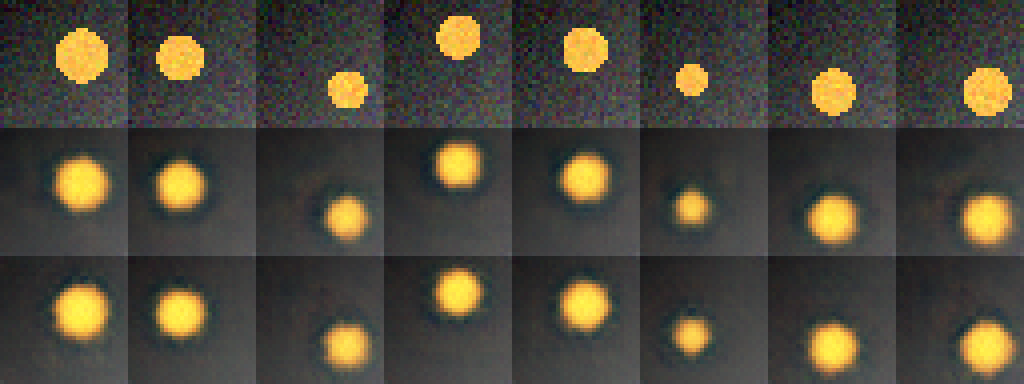

сохранены: comparison.png (оригинал | A | B), comparison_with_clean.png (чистая | зашумлённая | A | B), abs_error_vs_clean_x5.png


In [7]:
from PIL import Image
# чистые сцены: те же факторы и тот же генератор, что в L.dataset, но без шума (проверка совпадения ниже)
rng = np.random.default_rng(7)
f_all = rng.random((4096 + 1024, L.N_FACTORS[KIND]))
clean_np = np.stack([L.render(KIND, fi) for fi in f_all])
noisy_np = np.clip(clean_np + 0.05 * rng.standard_normal(clean_np.shape).astype(np.float32), 0, 1)
assert np.allclose(noisy_np[4096:], Xte.cpu().numpy()), "реконструкция данных не совпала с L.dataset"
CLEAN_TE = torch.tensor(clean_np[4096:], device=L.DEVICE); CLEAN_TR = torch.tensor(clean_np[:4096], device=L.DEVICE)
print("чистые сцены восстановлены, совпадение зашумлённых с L.dataset: да")

def to_row(t): return np.concatenate(list(t.permute(0, 2, 3, 1).cpu().numpy()), axis=1)
MODELS101 = {}
rows = [Xte[:8]]
for name, cfg in (("A", a_cfg), ("B", b_cfg)):
    model = L.run(KIND, cfg, 101)[1]; MODELS101[name] = model
    rows.append(L.reconstruct(model, Xte[:8], cfg["eval_noise"]))
grid = np.concatenate([to_row(r) for r in rows], axis=0)
sheet = Image.fromarray((grid * 255).round().astype("uint8")).resize((8 * 32 * 4, 3 * 32 * 4), Image.NEAREST)
sheet.save(OUT / "comparison.png"); display(sheet)
grid2 = np.concatenate([to_row(CLEAN_TE[:8])] + [to_row(r) for r in rows], axis=0)
Image.fromarray((grid2 * 255).round().astype("uint8")).resize((8 * 32 * 4, 4 * 32 * 4), Image.NEAREST).save(OUT / "comparison_with_clean.png")
diff = np.concatenate([to_row((r - CLEAN_TE[:8]).abs() * 5) for r in rows[1:]], axis=0).clip(0, 1)
Image.fromarray((diff * 255).round().astype("uint8")).resize((8 * 32 * 4, 2 * 32 * 4), Image.NEAREST).save(OUT / "abs_error_vs_clean_x5.png")
print("сохранены: comparison.png (оригинал | A | B), comparison_with_clean.png (чистая | зашумлённая | A | B), abs_error_vs_clean_x5.png")

## Ячейка 8. Диагностика по размеру латентного вектора для своего набора (шаг 8)

In [8]:
DSWEEP = {}
for d in (1, 2, 3, 4, 8):
    vals = [L.run(KIND, dict(L.BASE, d=d), s)[0]["psnr"] for s in (101, 102, 103)]
    DSWEEP[d] = vals
    print(f"d={d}: PSNR = {np.mean(vals):.2f} дБ (по seed: {', '.join(f'{v:.2f}' for v in vals)})")

d=1: PSNR = 19.60 дБ (по seed: 19.60, 19.67, 19.52)
d=2: PSNR = 21.44 дБ (по seed: 21.42, 21.55, 21.34)
d=3: PSNR = 22.75 дБ (по seed: 22.46, 22.45, 23.35)
d=4: PSNR = 23.27 дБ (по seed: 23.31, 23.20, 23.28)
d=8: PSNR = 22.78 дБ (по seed: 23.14, 23.29, 21.92)


## Ячейка 9. E1: потолок шума и качество относительно чистых сцен; значения по seed

In [9]:
CEIL = L.psnr_images(CLEAN_TE, Xte)
print(f"потолок: PSNR чистых сцен относительно зашумлённых тестовых эталонов = {CEIL:.3f} дБ")
PER = {"A": [], "B": []}
for s in L.SEEDS:
    for name, cfg in (("A", a_cfg), ("B", b_cfg)):
        m, model = L.run(KIND, cfg, s)
        rec_te = L.reconstruct(model, Xte); rec_tr = L.reconstruct(model, Xtr[:cfg["n_train"]][:512])
        PER[name].append(dict(seed=s, psnr_noisy=m["psnr"], gap=m["gap"], seconds=m["seconds"],
                              psnr_clean=L.psnr_images(rec_te, CLEAN_TE),
                              train_clean=L.psnr_images(rec_tr, CLEAN_TR[:cfg["n_train"]][:512]),
                              train_noisy=L.psnr_images(rec_tr, Xtr[:cfg["n_train"]][:512])))
for name in "AB":
    for r in PER[name]:
        print(f"{name} seed {r['seed']}: тест к зашумл. {r['psnr_noisy']:.2f} | тест к чистым {r['psnr_clean']:.2f} | "
              f"train к зашумл. {r['train_noisy']:.2f} | train к чистым {r['train_clean']:.2f} | gap {r['gap']:+.3f}")
for name in "AB":
    for key in ("psnr_noisy", "psnr_clean", "gap"):
        v = [r[key] for r in PER[name]]; print(f"{name} {key:10s}: {np.mean(v):.3f} ± {np.std(v, ddof=1):.3f}")

потолок: PSNR чистых сцен относительно зашумлённых тестовых эталонов = 26.091 дБ
A seed 101: тест к зашумл. 23.18 | тест к чистым 26.12 | train к зашумл. 23.22 | train к чистым 26.19 | gap +0.028
A seed 102: тест к зашумл. 23.43 | тест к чистым 26.70 | train к зашумл. 23.47 | train к чистым 26.78 | gap +0.028
A seed 103: тест к зашумл. 22.49 | тест к чистым 24.78 | train к зашумл. 22.51 | train к чистым 24.81 | gap +0.014
A seed 104: тест к зашумл. 23.20 | тест к чистым 26.20 | train к зашумл. 23.23 | train к чистым 26.25 | gap +0.018
A seed 105: тест к зашумл. 23.22 | тест к чистым 26.26 | train к зашумл. 23.26 | train к чистым 26.33 | gap +0.027
B seed 101: тест к зашумл. 22.89 | тест к чистым 25.62 | train к зашумл. 23.02 | train к чистым 25.84 | gap +0.131
B seed 102: тест к зашумл. 23.34 | тест к чистым 26.55 | train к зашумл. 23.48 | train к чистым 26.79 | gap +0.137
B seed 103: тест к зашумл. 22.42 | тест к чистым 24.68 | train к зашумл. 22.53 | train к чистым 24.83 | gap +0.105

## Ячейка 10. E2: почему нужно 160 эпох — 512 сцен при 20 эпохах (80 шагов)

In [10]:
E2 = [L.run(KIND, dict(b_cfg, epochs=20), s)[0] for s in L.SEEDS]
print("512 сцен, 20 эпох: PSNR на тесте", [round(m["psnr"], 2) for m in E2], "| среднее", round(np.mean([m["psnr"] for m in E2]), 2),
      "| gap", round(np.mean([m["gap"] for m in E2]), 3))

512 сцен, 20 эпох: PSNR на тесте [16.88, 16.6, 16.61, 16.8, 16.56] | среднее 16.69 | gap 0.082


## Ячейка 11. E3: динамика переобучения — 512 сцен, 20…320 эпох (seed 101)

In [11]:
E3 = {}
for ep in (20, 40, 80, 160, 320):
    m, model = L.run(KIND, dict(b_cfg, epochs=ep), 101)
    E3[ep] = dict(test=m["psnr"], gap=m["gap"], test_clean=L.psnr_images(L.reconstruct(model, Xte), CLEAN_TE))
    print(f"эпох {ep:3d} (шагов {ep * 4:4d}): тест {m['psnr']:.2f} дБ | к чистым {E3[ep]['test_clean']:.2f} | gap {m['gap']:+.3f}")

эпох  20 (шагов   80): тест 16.88 дБ | к чистым 17.29 | gap +0.082
эпох  40 (шагов  160): тест 21.75 дБ | к чистым 23.60 | gap +0.085
эпох  80 (шагов  320): тест 22.55 дБ | к чистым 24.95 | gap +0.105
эпох 160 (шагов  640): тест 23.05 дБ | к чистым 25.91 | gap +0.136
эпох 320 (шагов 1280): тест 23.72 дБ | к чистым 27.37 | gap +0.241


## Ячейка 12. Сводка и скачивание

In [12]:
import uuid, shutil
SESSION = uuid.uuid4().hex[:8]
ENV = dict(gpu=torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu", torch=torch.__version__, cuda=torch.version.cuda,
           python=sys.version.split()[0], numpy=numpy.__version__, platform=platform.platform())
SUMMARY = dict(session=SESSION, utc=datetime.datetime.now(datetime.timezone.utc).isoformat(), env=ENV, variant=N, kind=KIND,
               factor=L.FACTORS[k], settings=dict(A=a_cfg, B=b_cfg), rows=ROWS, baseline=BASELINE, demo_variant1=DEMO_ROWS,
               d_sweep=DSWEEP, noise_ceiling=CEIL, per_seed=PER, e2_512_20ep=E2, e3_epochs=E3)
(OUT / f"summary_{SESSION}.json").write_text(json.dumps(SUMMARY, ensure_ascii=False, indent=2, default=str), encoding="utf-8")
shutil.copy("comparison_variant01.png", OUT / "comparison_variant01.png")
shutil.make_archive(f"lab07_v18_artifacts_{SESSION}", "zip", "artifacts")
print("Сеанс", SESSION)
try:
    from google.colab import files; files.download(f"lab07_v18_artifacts_{SESSION}.zip")
except Exception as e: print("Скачайте zip из панели «Файлы»:", e)

Сеанс 32fd89a7


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## После выполнения
«Файл» → «Скачать» → «.ipynb». Обучение на GPU не побитово детерминировано: при повторе значения совпадут в пределах разброса между seed,
а не до последнего знака (это отмечено и в МУ).